# Notebook 1 — Prompt Engineering

A large language model (LLM) reads text and writes text. The text you send is the
**prompt**. **Prompt engineering** means writing the prompt so that the model gives a useful
answer, in the format you want, every time.

**What you will learn**

1. How to send a request to a chat model.
2. What tokens are, and how a model picks the next word.
3. The main prompting techniques: zero-shot, few-shot, chain-of-thought, self-consistency,
   and role prompting.
4. How to reuse prompts with templates.

**Before you start**

```bash
ollama pull gpt-oss:20b   # main model
ollama pull qwen3:1.7b    # small model, used in sections 8 and 9
uv sync
```

Then choose the `.venv` Python kernel for this notebook. ⏱️ About 45 minutes.

## 1. Setup

The `roadmap` package (in `src/roadmap/`) has two small helpers:

| Helper | What it does |
|---|---|
| `get_client()` | Returns an Ollama client. |
| `ask(prompt)` | Sends a prompt and returns the answer as text. |

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from roadmap import ask, get_client, get_settings

MODEL = get_settings().chat_model
print("Chat model:", MODEL)

ASSETS = Path("assets")
ASSETS.mkdir(exist_ok=True)

Chat model: gpt-oss:20b


## 2. Your first chat request

![How a chat request works](assets/chat_request.svg)

A chat model gets a list of **messages**. Each message has a **role**:

| Role | Meaning |
|---|---|
| `system` | Rules for the whole conversation, for example "be short". |
| `user` | The question or task. |
| `assistant` | The model's earlier answers. You add them to continue a conversation. |

In [2]:
client = get_client()
response = client.chat(
    model=MODEL,
    messages=[
        {"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "In one sentence, what is a large language model?"},
    ],
    think="low",
    options={"temperature": 0},
)

print("Thinking:", response.message.thinking)
print("Answer:  ", response.message.content)
print("Tokens:   prompt =", response.prompt_eval_count, "| answer =", response.eval_count)

Thinking: Need concise one sentence.
Answer:   A large language model is a neural network trained on vast amounts of text that learns statistical patterns to generate, predict, or understand human language.
Tokens:   prompt = 92 | answer = 43


**Two things to notice:**

- `gpt-oss` is a **reasoning model**. It writes a short "thinking" text first and then the
  answer. `think="low"` asks for short thinking. The thinking text is kept apart from the answer.
- The model counts its work in **tokens**: tokens in the prompt and tokens in the answer
  (thinking included). Speed, cost, and limits are all measured in tokens.

From now on we use the shorter `ask()` helper. It does the same request and returns only the
answer.

In [3]:
print(ask("Say hello and tell me in one short sentence what you can do."))

Hello! I can answer questions, generate text, help with ideas, and chat about almost anything.


## 3. Tokens

> **Token:** a small piece of text, such as a word, part of a word, a number, or a punctuation
> mark. Each token has a number (its **id**). The model only sees these numbers.
>
> **Context window:** the maximum number of tokens (prompt + answer) a model can handle at once.

![Text to tokens to token ids](assets/tokenization.svg)

Let's split some text with the real `gpt-oss` tokenizer. `␣` marks a token that starts with a
space.

In [4]:
from tokenizers import Tokenizer

tokenizer = Tokenizer.from_pretrained("openai/gpt-oss-20b")

samples = {
    "English": "Tokenization splits text into sub-word pieces.",
    "Turkish": "Belgeleri parçalara ayırmak arama kalitesini artırır.",
    "Code": "def add(a, b): return a + b",
    "Numbers": "In 2026, 12345 x 678 = 8369910",
}

for label, text in samples.items():
    encoding = tokenizer.encode(text)
    pieces = [text[start:end].replace(" ", "␣") for start, end in encoding.offsets]
    print(f"{label:<8} {len(text):>2} characters -> {len(pieces):>2} tokens")
    print("        ", " | ".join(pieces))

English  46 characters ->  9 tokens
         Token | ization | ␣splits | ␣text | ␣into | ␣sub | -word | ␣pieces | .
Turkish  53 characters -> 16 tokens
         Belg | eleri | ␣par | çal | ara | ␣ay | ır | mak | ␣ar | ama | ␣kal | ites | ini | ␣artır | ır | .
Code     27 characters -> 10 tokens
         def | ␣add | (a | , | ␣b | ): | ␣return | ␣a | ␣+ | ␣b
Numbers  30 characters -> 16 tokens
         In | ␣ | 202 | 6 | , | ␣ | 123 | 45 | ␣x | ␣ | 678 | ␣= | ␣ | 836 | 991 | 0


**What to notice**

- Common English words are often one token. Rare words are split into pieces.
- Turkish needs about **twice as many tokens** as English for a sentence of the same length.
  More tokens means slower answers and a fuller context window.
- Numbers are split into small groups of digits. This is one reason LLMs make maths mistakes.

## 4. How the model picks the next word

![Text is generated one token at a time](assets/next_token_loop.svg)

The model writes **one token at a time**. At each step it gives every possible next token a
score, turns the scores into probabilities, and picks one token. Then it adds that token to
the text and repeats.

Two settings control the pick:

> **Temperature:** how "adventurous" the pick is. Low temperature (close to 0) almost always
> picks the most likely token, so answers are stable. High temperature (above 1) gives less
> likely tokens a chance, so answers are more varied and creative, but also riskier.
>
> **Top-p:** keeps only the most likely tokens until their probabilities add up to `p`
> (for example 0.9), and ignores the rest.

Here is a toy example: the next word after *"The cat sat on the …"*.

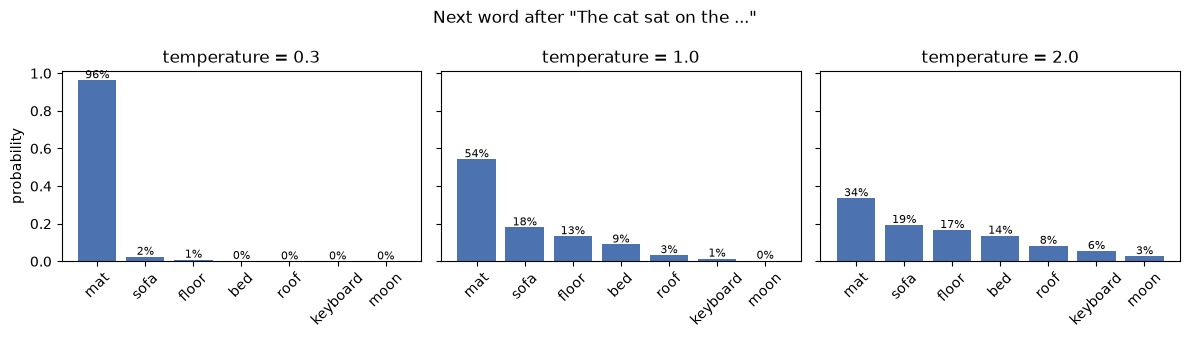

In [5]:
words = ["mat", "sofa", "floor", "bed", "roof", "keyboard", "moon"]
scores = np.array([4.0, 2.9, 2.6, 2.2, 1.2, 0.4, -1.0])


def to_probabilities(scores, temperature=1.0):
    scaled = scores / temperature
    exp = np.exp(scaled - scaled.max())
    return exp / exp.sum()


fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, temperature in zip(axes, [0.3, 1.0, 2.0], strict=True):
    probs = to_probabilities(scores, temperature)
    ax.bar(words, probs, color="#4C72B0")
    ax.set_title(f"temperature = {temperature}")
    ax.tick_params(axis="x", rotation=45)
    for i, p in enumerate(probs):
        ax.text(i, p + 0.01, f"{p:.0%}", ha="center", fontsize=8)
axes[0].set_ylabel("probability")
fig.suptitle('Next word after "The cat sat on the ..."')
fig.tight_layout()
fig.savefig(ASSETS / "temperature.png", dpi=120)
plt.show()

Low temperature puts almost all probability on "mat". High temperature spreads it out.

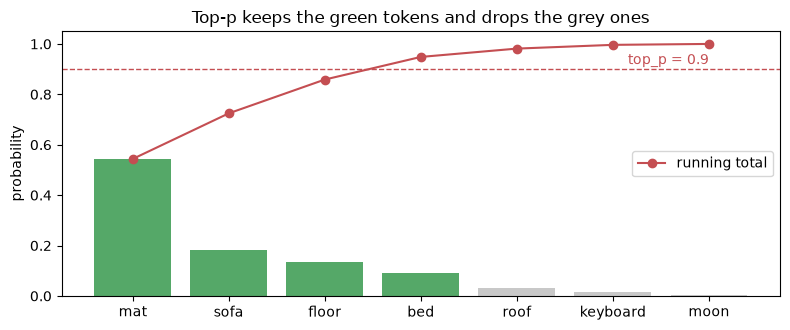

In [6]:
top_p = 0.9
probs = to_probabilities(scores)
order = np.argsort(probs)[::-1]
sorted_words = [words[i] for i in order]
sorted_probs = probs[order]
running_total = np.cumsum(sorted_probs)

# Keep tokens until the running total reaches top_p.
keep = running_total - sorted_probs < top_p
colors = ["#55A868" if k else "#C8C8C8" for k in keep]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(sorted_words, sorted_probs, color=colors)
ax.plot(sorted_words, running_total, marker="o", color="#C44E52", label="running total")
ax.axhline(top_p, linestyle="--", color="#C44E52", linewidth=1)
ax.text(len(words) - 1, top_p + 0.02, f"top_p = {top_p}", ha="right", color="#C44E52")
ax.set_ylabel("probability")
ax.set_title("Top-p keeps the green tokens and drops the grey ones")
ax.legend(loc="center right")
fig.tight_layout()
fig.savefig(ASSETS / "top_p.png", dpi=120)
plt.show()

## 5. Temperature in practice

The same prompt, three times at temperature 0 and three times at 1.3:

In [7]:
prompt = "Invent a name for a coffee shop run by robots. Reply with the name only."

for temperature in (0.0, 1.3):
    names = [ask(prompt, temperature=temperature, seed=i) for i in range(3)]
    print(f"temperature={temperature}: {names}")

temperature=0.0: ['RoboRoast Café', 'RoboRoast Café', 'RoboRoast Café']


temperature=1.3: ['ByteBrew Café', 'RoboBrew Café', 'Circuit Brew Café']


**Rule of thumb:** use a temperature near 0 for facts, data extraction, and anything you want
to test. Use a higher temperature for ideas and creative writing.

## 6. Zero-shot prompting

![Zero-shot, one-shot, and few-shot prompts](assets/prompt_shots.svg)

> **Zero-shot prompting:** you describe the task, but you give **no examples**.

This works well for common tasks. Two habits help a lot: **list the allowed answers**, and
**say how the answer should look**.

In [8]:
prompt = """Is the statement true or false? Reply with one word.

Statement: The Eiffel Tower is in Berlin."""

print(ask(prompt))

False


In [9]:
reviews = [
    "The battery lasts two full days and the screen is beautiful.",
    "It stopped charging after a week and support never replied.",
    "It does what it says. Nothing more, nothing less.",
]

for review in reviews:
    prompt = (
        "Is this product review positive, negative, or neutral? "
        "Reply with one word.\n\n"
        f"Review: {review}"
    )
    print(f"{ask(prompt):<9} <- {review}")

Positive  <- The battery lasts two full days and the screen is beautiful.


Negative  <- It stopped charging after a week and support never replied.


Neutral   <- It does what it says. Nothing more, nothing less.


## 7. One-shot and few-shot prompting

> **One-shot / few-shot prompting:** you add one example (one-shot) or a few examples
> (few-shot) to the prompt. The model copies the pattern of the examples. This is also called
> **in-context learning**: the model learns the task from the prompt, without extra training.

Examples are the best way to control the **format** of the answer.

In [10]:
prompt = """Translate English to French.

English: How is the weather today?
French: Quel temps fait-il aujourd'hui ?

English: Where is the nearest supermarket?
French:"""

print(ask(prompt))

French: Où se trouve le supermarché le plus proche ?


Few-shot prompts are great for turning messy text into clean fields. The two examples below
show the exact output format we want:

In [11]:
prompt = """Extract the method, path, and status code from each log line.

Log: GET /api/v1/users HTTP/1.1 200 123 "-" "curl/8.5.0"
Fields: method=GET | path=/api/v1/users | status=200

Log: POST /login HTTP/1.1 401 89 "https://example.com/" "Mozilla/5.0"
Fields: method=POST | path=/login | status=401

Log: PUT /api/v1/users/42 HTTP/1.1 204 0 "https://example.com/admin" "PostmanRuntime/7.37"
Fields:"""

print(ask(prompt))

Fields: method=PUT | path=/api/v1/users/42 | status=204


In [12]:
prompt = """Classify the emotion in each statement.

Statement: I just won my first marathon!
Emotion: joy

Statement: I can't believe I lost my keys again.
Emotion: frustration

Statement: My best friend is moving to another country.
Emotion: sadness

Statement: That movie was so scary I had to cover my eyes.
Emotion:"""

print(ask(prompt))

Emotion: fear


## 8. Chain-of-thought prompting

> **Chain-of-thought (CoT):** you ask the model to write its steps before the final answer.
> Each written step becomes input for the next one, so the model has "room to think".
> This helps with maths, logic, and multi-step problems.

![Direct answer vs. chain-of-thought](assets/chain_of_thought.svg)

`gpt-oss` already thinks step by step inside (that is what the "thinking" text is). To see
the effect of CoT clearly, we use a **small model with thinking turned off**.

For the direct answer we also set a very small token limit, so the model cannot write any
steps.

In [13]:
SMALL_MODEL = "qwen3:1.7b"
question = (
    "A patch of lily pads doubles in size every day. It takes 48 days to cover the whole "
    "lake. How many days does it take to cover half of the lake?"
)

direct = ask(
    f"{question}\nReply with the final answer only, no explanation.",
    model=SMALL_MODEL,
    think=False,
    max_tokens=12,
)
step_by_step = ask(
    f"{question}\nSolve it step by step, then give the final answer.",
    model=SMALL_MODEL,
    think=False,
)

print("Direct answer:", direct)
print("\nStep by step:\n", step_by_step)

Direct answer: 24

Step by step:
 We are told that a patch of lily pads **doubles in size every day**. It takes **48 days** to cover the entire lake.

We are asked:  
**How many days does it take to cover half of the lake?**

---

### Step-by-step reasoning:

Let’s denote:

- Let the initial size of the patch be **1 unit** (e.g., 1 square unit).
- Every day, the size **doubles**.
- After **1 day**, it becomes **2 units**.
- After **2 days**, it becomes **4 units**.
- ...
- After **n days**, it becomes **2ⁿ units**.

We are told that it takes **48 days** to cover the entire lake. So:

$$
2^{48} = \text{size of the lake}
$$

We are asked: **How many days does it take to cover half of the lake?**

That is, we want to know how many days it takes for the patch to reach **half the size** of the lake.

Since the size doubles every day, the size of the patch is:

$$
\text{Size after } n \text{ days} = 2^n
$$

We want to find the smallest $ n $ such that:

$$
2^n = \frac{1}{2} \cdot 2^{48} = 2^

The direct answer falls into the trap ("half of 48 is 24"). With the steps written out, the
model sees that the lake is half full one day before it is full: day 47.

Large models and reasoning models often get this right anyway. Small models gain the most
from CoT.

## 9. Self-consistency

> **Self-consistency:** you ask the same question several times with a temperature above 0,
> so you get different chains of reasoning. Then you take a **majority vote** on the final
> answers. Wrong answers tend to differ from each other, while correct answers tend to agree.

![Self-consistency](assets/self_consistency.svg)

We use the small model again, because its answers change more from run to run.

In [14]:
question = "When I was 6 my sister was half my age. Now I am 70. How old is my sister?"
prompt = f"{question}\nThink step by step. End with a last line: 'Answer: <number>'."


def final_number(text: str) -> str:
    numbers = re.findall(r"Answer\W*(-?\d+)", text)
    return numbers[-1] if numbers else "no answer"


answers = [
    final_number(ask(prompt, model=SMALL_MODEL, think=False, temperature=0.9, seed=i))
    for i in range(9)
]
votes = Counter(answers)
print("Answers:", answers)
print("Majority vote:", votes.most_common(1)[0][0])

Answers: ['64', '67', '67', '67', '67', '67', '67', '4', '67']
Majority vote: 67


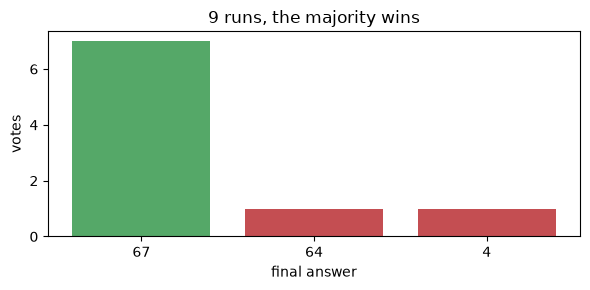

In [15]:
labels, counts = zip(*votes.most_common(), strict=True)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(labels, counts, color=["#55A868"] + ["#C44E52"] * (len(labels) - 1))
ax.set_xlabel("final answer")
ax.set_ylabel("votes")
ax.set_title(f"{len(answers)} runs, the majority wins")
fig.tight_layout()
fig.savefig(ASSETS / "self_consistency_votes.png", dpi=120)
plt.show()

The cost: 9 runs use about 9 times the tokens. Use self-consistency when a correct answer
matters more than speed or cost.

## 10. Role prompting

> **Role prompting:** you give the model a role in the system message, for example "You are a
> teacher for children". The role changes the words, the depth, and the tone of the answer.

In [16]:
question = "What is an API?"
roles = {
    "teacher for 10-year-olds": "You are a friendly teacher for 10-year-olds. Use one example.",
    "senior engineer": "You are a senior backend engineer talking to a new colleague.",
}

for name, system in roles.items():
    print(f"=== {name} ===")
    print(ask(question, system=f"{system} Answer in at most three sentences."), "\n")

=== teacher for 10-year-olds ===


An API (Application Programming Interface) is like a menu in a restaurant that tells you what dishes you can order and how to order them. For example, a weather app uses an API to ask a weather website, “What’s the temperature in New York?” and the website sends back the answer. So, an API is just a set of rules that lets different computer programs talk to each other. 

=== senior engineer ===


An API (Application Programming Interface) is a set of rules and endpoints that let different software components talk to each other, usually over HTTP. It defines the data formats, methods, and authentication needed to request and receive information. Think of it as a contract that lets one service expose functionality to others without exposing its internal code. 



## 11. Prompt templates

![A prompt template is a prompt with blanks](assets/prompt_template.svg)

Real apps send the same prompt again and again with different inputs. A **prompt template**
is a prompt with named blanks like `{text}`. You fill the blanks for each request.

Look at the `qa` template: it tells the model to answer **only from the given context** and to
say "I don't know" otherwise. This idea is called **grounding**. It is the base of RAG
(retrieval-augmented generation), which we build in Stage 2.

In [17]:
TEMPLATES = {
    "qa": (
        "Answer the question using only the context. If the answer is not in the context, "
        "reply exactly: I don't know.\n\nContext: {context}\n\nQuestion: {question}"
    ),
    "classify": (
        "Classify the text into exactly one of these categories: {categories}. "
        "Reply with the category only.\n\nText: {text}"
    ),
    "sql": "Write one SQL query for this request. Reply with SQL only.\n\nRequest: {request}",
}


def run(template_name: str, **values: str) -> str:
    return ask(TEMPLATES[template_name].format(**values))


planets = (
    "The inner planets Mercury, Venus, Earth, and Mars are rocky. "
    "The outer planets Jupiter, Saturn, Uranus, and Neptune are gas or ice giants."
)
print(run("qa", context=planets, question="Which planets are rocky?"))
print(run("qa", context=planets, question="How many moons does Jupiter have?"))
print(run("classify", categories="music, food, sports", text="The concert was amazing."))
print(
    run(
        "sql",
        request=(
            "Names and emails of customers (table customers) who bought something in the "
            "last 30 days (table purchases with customer_id and purchase_date)."
        ),
    )
)

Mercury, Venus, Earth, and Mars.


I don't know.


music


```sql
SELECT DISTINCT c.name, c.email
FROM customers c
JOIN purchases p
  ON c.id = p.customer_id
WHERE p.purchase_date >= CURRENT_DATE - INTERVAL '30' DAY;
```


## 12. Summary

| Technique | Use it when | How |
|---|---|---|
| Zero-shot | The task is common and clear | Instruction + allowed answers + format |
| One-/few-shot | You need an exact format or labels | 1–5 examples, then the new input |
| Chain-of-thought | The task has several steps | "Solve it step by step, then …" |
| Self-consistency | A correct answer matters more than cost | Several runs + majority vote |
| Role prompting | You need a certain tone or depth | System message: "You are …" |
| Templates | Same prompt, different inputs | Named blanks, filled per request |

**Settings:** low temperature for facts and tests, higher temperature for creative tasks.
Reasoning models need room for their thinking, so do not set the token limit too low.

➡️ **Next:** Notebook 2 — LangChain building blocks.